# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [17]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [18]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [19]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [20]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [21]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [22]:
QUESTION = "Яка столиця Франції?"

In [23]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [24]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [25]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.1 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.9 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [26]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.6 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [27]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [28]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [29]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [30]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [31]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [32]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.05,8.64,12.34,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.71,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.97,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.03,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

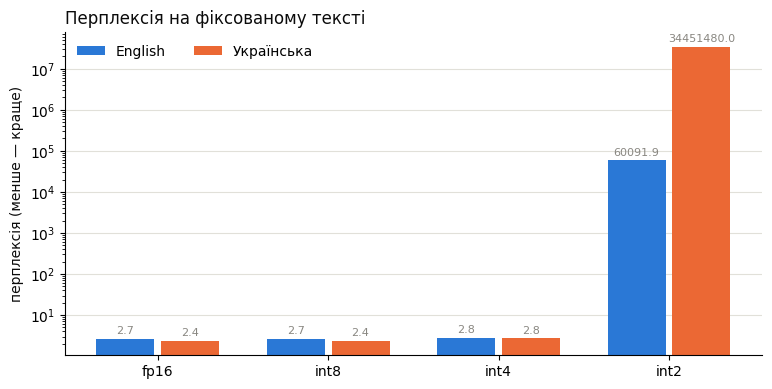

In [33]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [34]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [35]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [36]:
VOTES = {1: "B", 2: "B", 3: "=", 4: "B", 5: "="}

In [37]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 1, int4 краща: 2, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [38]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

## 0.1. Теоретичні питання

1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

**Відповідь**:

Мовні моделі не бачать текст по окремих літерах; вони обробляють його шматками — токенами, на які текст розбиває токенізатор. Слово «трансформер» для моделі виглядає не як набір літер, а як кілька неподільних токенів. Оскільки модель оперує саме цими блоками, вона не може поринути всередину токена і просто порахувати букви.

from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B-Base")
tokens = tokenizer.tokenize("трансформер")
print(f"Токени слова 'трансформер': {tokens}")

2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

**Відповідь:**

Найбільший стрибок відбувається між int4 та int2. У 4-бітному форматі втрати якості ще невеликі. Проте в int2 для кожного параметра залишається "лише 4 можливі значення на вагу", через що архітектура моделі ламається і вона починає видавати незв'язний текст

3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

**Відповідь:**

Ні, перплексія для української мови зростає значно швидше і стрімкіше, ніж для англійської. Це підтверджує інформація із лекції: при жорсткій квантизації першими деградують математика та "мови з нелатинською абеткою — зокрема й українська". Англійська мова залишається більш стійкою.

4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

**Відповідь:**

Мій вибір у сліпому порівнянні не зовсім збігся з тим, що показали автоматичні метрики. Автоматичні метрики демонструють невелике, але стабільне погіршення якості для int4 порівняно з fp16. Проте під час оцінювання очима int4 перемогла з рахунком 2:1. Така різниця виникла через те, що на вільному тексті модель fp16 згенерувала стилістично гірше формулювання (наприклад, абсурдне та грубе звернення «Увага, викладаче!» у першому запиті). Це наочно показує дві речі: по-перше, автоматичні метрики не завжди здатні вловити стилістичну різницю та адекватність тексту; по-друге, вибірка лише з 5 порівнянь є замалою для надійних висновків.

5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

**Відповідь:**

У розділі 2.4 модель іноді використовує синоніми або змінює порядок слів (наприклад, замість еталонного «надішліть мені звіт» генерує варіанти з іншими формулюваннями). На такі зміни метрика BLEU реагує різким падінням, оскільки вона є дуже суворою і вимагає точного збігу послідовностей слів (навіть правильний синонім знижує бал). Метрика chrF реагує значно м'якше і знижується менш стрімко, оскільки вона порівнює послідовності символів, що робить її більш стійкою до синонімів чи зміни закінчень.

6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

**Відповідь:**
Пам'ять зменшилася, але не рівно у 2, 4 чи 8 разів, оскільки бібліотека Quanto квантизує лише ваги лінійних шарів (nn.Linear). Ембединги, нормалізації, вихідний шар, а також додатковий overhead (KV-кеш, активації, буфери рантайму) залишаються у 16-бітному форматі й займають сталий обсяг пам'яті. Генерація тексту на GPU T4 не стала швидшою (і може навіть сповільнюватися), оскільки відеокарта T4 не вміє апаратно множити 4- чи 2-бітні числа; через це перед кожним обчисленням ваги доводиться програмно розпаковувати назад у 16 біт.

7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

**Відповідь:**

Base-модель пройшла лише етап попереднього тренування на текстах з інтернету, тому вона вміє лише передбачати наступний токен, а не вести діалог як асистент. Запит «Яка столиця Франції?» вона сприймає як початок списку запитань для вікторини і просто продовжує цей список новими питаннями. Щоб модель дала відповідь, промпт потрібно сформулювати як незавершене твердження, яке вона логічно продовжить.

8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

**Відповідь:**

У розділі 1.4 режим без міркувань (think=False) згенерував 252 токени за 71.5 секунди. Натомість режим із міркуваннями (think=True) згенерував 767 токенів і витратив на це аж 240.0 секунд. Тобто міркування забрали втричі більше токенів і в понад 3 рази більше часу.
Модель міркує англійською мовою, оскільки під час навчання логічних здібностей (Chain-of-Thought) переважна більшість високоякісних прикладів і датасетів була англомовною. Тому для моделі англійська залишається «найсильнішою» та найефективнішою мовою для побудови логічних ланцюжків і математичних висновків, після чого вона просто перекладає готовий результат на українську мову.

9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

**Відповідь:**

Відповідь без міркувань (think=False): Останній шматок він відріже на 10-й день. (Модель помиляється, просто ділячи 10 на 1).Відповідь з міркуваннями (think=True): Після 8 днів у кравця залишиться 2 метри тканини. На 9-й день він відріже 1 метр, і в нього залишиться рівно 1 метр. Це і буде останній шматок. Отже, останній розріз буде зроблено на 9-й день. Відповідь: 9. (Модель завдяки розбиттю на кроки помічає логічну пастку і дає правильну відповідь)

10. У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

**Відповідь:**

У функціях generate_raw і chat параметри temperature: 0 і seed: 1 використовуються для фіксації випадковості (детермінованості) генерації. Параметр temperature: 0 змушує модель завжди обирати найімовірніший наступний токен, прибираючи креативність. Параметр seed: 1 додатково фіксує початкове значення генератора випадкових чисел. Це критично важливо для бенчмарків і тестування: однакові параметри гарантують, що при повторних запусках на одному й тому ж запиті модель видаватиме абсолютно ідентичну відповідь, що дозволяє чесно порівнювати різні варіанти квантизації.

11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

**Відповідь:**

У секції 2 використовується формат fp16 замість bf16, оскільки серверні відеокарти покоління Turing, до яких належить T4, не підтримують формат bf16 на апаратному рівні. Функція torch.cuda.get_device_capability() на T4 повертає (7, 5) (де 7 — це архітектура Turing). Апаратна підтримка bf16 (і прискорення від нових ядер Quanto) з'явилася лише в архітектурі Ampere (capability 8.0 і вище, наприклад, A100 або L4). На T4 виконання bf16 емулювалося б програмно, що було б надзвичайно повільно.

12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

**Відповідь:**

У моделі Qwen3-4B-Instruct-2507 приблизно 4 мільярди параметрів (4B).
За формулою з лекції для формату fp16 (2 байти на параметр) базовий розмір ваг становить: 4 × 2 = 8 GB.
Згідно з таблицею у розділі 2.4 (рядок fp16), "памʼять моделі" становить 8.05 GB. Розраховане значення ідеально збігається з фактичною пам'яттю, виділеною під ваги моделі на відеокарті.

13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

**Відповідь:**

Перплексія — це автоматична метрика, яка показує «невпевненість» моделі при передбаченні наступного токена (з якої кількості варіантів вона вагалася, обираючи наступне слово). Її не можна порівнювати між різними мовами (наприклад, англійською та українською), оскільки токенізатор по-різному розбиває ці мови на токени, і базова ймовірність токенів відрізняється.
Перплексія на випадкових словах: 52.44.
Пояснення результату: Це значення у понад 20 разів більше, ніж перплексія на осмисленому українському тексті (яка становила 2.40). Це пояснюється тим, що після слова «крісло» модель статистично очікує прийменник, дієслово або сполучник (наприклад, «стоїть» або «і»), а не інший непов'язаний іменник «яблуко». Через відсутність граматичного зв'язку та контексту моделі дуже складно передбачити наступний токен, тому її «невпевненість» різко зростає.

14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

**Відповідь:**

Згідно з таблицею, пік VRAM для fp16 становив 8.64 GB, тоді як ваги моделі займали лише 8.05 GB. Пік VRAM завжди більший, тому що під час генерації тексту пам'ять потрібна не лише для збереження самих ваг, але й для додаткового навантаження (overhead): KV-кешу (який збільшується з кожним новим токеном), проміжних активацій нейронів та внутрішніх буферів рантайму.

15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

**Відповідь:**

У моєму сліпому порівнянні я обрала fp16 1 раз, int4 — 2 рази, і ще 2 рази оцінила відповіді як «однакові». З 5 порівнянь робити надійні висновки неможливо, оскільки вибірка занадто мала і на неї сильно впливає випадковість (одне невдале формулювання може змінити переможця). Для надійного, статистично значущого висновку потрібно протестувати фіксований набір хоча б із 15–20 різноманітних промптів

16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

**Відповідь:**

У форматі int2 модель повністю ламається і втрачає здатність генерувати зв'язний текст. Вона видає безглуздий набір повторюваних символів (наприклад, 000000000, \\\\\\\\), англійські слова без контексту (ever, taken, between) та зламане форматування. Ознаки такого збою в int4 ще не помітні: 4-бітна модель продовжує успішно будувати логічні, граматично правильні українські речення, хоч і може іноді поступатися стилістикою оригінальній моделі.

17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

**Відповідь:**

Квантизація значно сильніше б'є по менших моделях (наприклад, 1.7B), ніж по більших (4B чи 70B). У малій моделі параметрів і так небагато, тому кожен з них має більшу вагу для загального результату. Через це втрата точності при округленні до 4 чи 2 біт призводить до різкішого стрибка перплексії та більшого падіння метрик перекладу (chrF, BLEU) порівняно з моделлю на 4B. Менші моделі швидше втрачають логіку при квантизації.

18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

**Відповідь:**

Параметр OLLAMA_NUM_PARALLEL задає кількість запитів (слотів), які сервер Ollama може обробляти одночасно (паралельно). За замовчуванням сервер може обробляти запити по черзі, але зміна цього параметра вмикає паралелізм (concurrency). Це дозволяє обслуговувати кількох клієнтів одночасно (наприклад, OLLAMA_NUM_PARALLEL=4), що ділить ресурси між ними, підвищуючи загальну пропускну здатність (throughput) сервера під навантаженням

19. Чому майже всі сучасні моделі зберігаються в bf16?

**Відповідь:**

Майже всі сучасні моделі зберігаються у форматі bf16 (brain floating point), оскільки він є "безпечнішим" за стандартний fp16. Формат bf16 має ширший діапазон для експоненти (8 біт проти 5 у fp16), що дозволяє йому записувати набагато більші числа. Це запобігає переповненню пам'яті (появі нескінченності inf або помилок NaN) під час обчислень активацій, які в трансформерах через ефект "викидів" можуть раптово досягати тисяч.

20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

**Відповідь:**

Рантайми (Ollama, llama.cpp, vLLM тощо) використовують OpenAI-сумісний API (протокол OpenAI), щоб розробникам не доводилося переписувати код клієнта при зміні сервера. Це єдиний стандартний HTTP-інтерфейс (з тими самими адресами, наприклад /v1/chat/completions). Завдяки цьому застосунок чи скрипт, який створювався для взаємодії з ChatGPT (за допомогою офіційної Python-бібліотеки openai), зможе без жодних змін у коді працювати з твоєю локальною моделлю — достатньо лише змінити змінну base_url на localhost замість серверів OpenAI.

In [39]:
PROMPT = "Столиця Франції — це місто "
print(generate_raw(BASE_MODEL, PROMPT, max_tokens=10))

1. Напишіть це слов


In [46]:
PROMPT = "Швець має шматок тканини довжиною 10 метрів. Кожного дня він відрізає по 1 метру. На який день він відріже останній шматок?"
compare_thinking(PROMPT)

=== think=False | токенів: 315 | генерація: 2.9 с
--- відповідь:
Давайте розглянемо задачу:

**Швец має шматок тканини довжиною 10 метрів. Кожного дня він відрізає по 1 метру. На який день він відріже останній шматок?**

### Розуміння задачі:
- Швец відрізає **1 метр** кожного дня.
- Він має **10 метрів** тканини.
- Він відріже **один метр** кожного дня.

### Розрахунок:
- Якщо він відрізає 1 метр кожного дня, то **10 днів** він відріже **10 метрів**.
- Після 10 днів — він відріже **10 метрів**, і **останній шматок** буде відрізаний **10-ти днійний**.

### Відповідь:
**Останній шматок відріже 10-ти днійний.**

---

**Відповідь: 10-й день.**

=== think=True | токенів: 1284 | генерація: 12.0 с
--- міркування (3112 символів), початок:
Okay, let's see. So the problem is about Швець who has a piece of fabric that's 10 meters long. Each day, he cuts off 1 meter. The question is, on which day will he cut off the last piece?

Hmm, let's break it down. If he cuts 1 meter each day, then after da

In [44]:
model_test = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)

print("Перплексія на випадкових словах:", perplexity(model_test, "крісло яблуко летіти радість швидко"))

del model_test
import gc
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Перплексія на випадкових словах: 52.440921783447266


In [48]:
%pip install -q openai
!python bench.py --base-url http://localhost:11434/v1 --model qwen3:1.7b --label before --reasoning-effort none

Прогрів: qwen3:1.7b на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     0.04с     0.05с          109.4       106.8
        2        0     1.46с     1.89с          110.7       108.5
        4        0     3.39с     5.35с          113.8       111.9
        8        0     7.33с     9.04с          114.7       112.3
Результати дописано в bench_results.csv


In [50]:
from openai import OpenAI

client = OpenAI(base_url="http://localhost:11434/v1", api_key="local")

prompts = [
    "Створи 5 цікавих карток для квізу на тему 'Кінематограф 90-х років'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Видатні українські художники'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Популярні страви італійської кухні'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Музичний гурт Queen'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Географія: найменші країни світу'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Всесвіт Marvel: головні персонажі'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Відомі архітектурні пам'ятки Парижа'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Наука: цікаві факти про космос'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Відеоігри жанру RPG'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Література: твори Тараса Шевченка'. Формат: Питання - Відповідь."
]

for i, p in enumerate(prompts, 1):
    print(f"\n--- Промпт {i}: {p} ---")
    response = client.chat.completions.create(
        model="qwen3:1.7b",
        messages=[{"role": "user", "content": p}],
        temperature=0.6,
        max_tokens=800
    )
    print(response.choices[0].message.content)


--- Промпт 1: Створи 5 цікавих карток для квізу на тему 'Кінематограф 90-х років'. Формат: Питання - Відповідь. ---


--- Промпт 2: Створи 5 цікавих карток для квізу на тему 'Видатні українські художники'. Формат: Питання - Відповідь. ---
**Питання - Відповідь**  

1. **Чи був Іван Франків у зміні стилів художниць?**  
   **Відповідь:** Так, він відомий як символістський художник, який винайшов новий стиль у українській мистецтві.  

2. **Якого стилів відомий Левко Дружков?**  
   **Відповідь:** Його відомий стилем є реалізм, який відображає життя і справжність у своїх картин.  

3. **Що використовував Іван Дебі для відображення життя?**  
   **Відповід

--- Промпт 3: Створи 5 цікавих карток для квізу на тему 'Популярні страви італійської кухні'. Формат: Питання - Відповідь. ---
**Питання - Відповідь**  
1. **Що є найбільш відомим італійським піцією?**  
   **Піцца Марджерія** — відома через її зелену, жовтому та синій відтінки.  

2. **Як називається відому пасту з томатом?**  
   **

In [60]:
!ollama pull qwen:0.5b

!python bench.py --base-url http://localhost:11434/v1 --model qwen:0.5b --label after --reasoning-effort none


Прогрів: qwen:0.5b на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     0.02с     0.04с          285.6       262.9
        2        0     0.37с     0.83с          260.9       254.1
        4        0     1.02с     1.57с          283.4       273.5
        8        0     2.46с     3.07с          258.9       254.9
Результати дописано в bench_results.csv


In [61]:
from openai import OpenAI

client = OpenAI(base_url="http://localhost:11434/v1", api_key="local")

prompts = [
    "Створи 5 цікавих карток для квізу на тему 'Кінематограф 90-х років'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Видатні українські художники'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Популярні страви італійської кухні'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Музичний гурт Queen'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Географія: найменші країни світу'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Всесвіт Marvel: головні персонажі'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Відомі архітектурні пам'ятки Парижа'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Наука: цікаві факти про космос'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Відеоігри жанру RPG'. Формат: Питання - Відповідь.",
    "Створи 5 цікавих карток для квізу на тему 'Література: твори Тараса Шевченка'. Формат: Питання - Відповідь."
]

for i, p in enumerate(prompts, 1):
    print(f"\n--- Промпт {i} (qwen:0.5b) ---")
    response = client.chat.completions.create(
        model="qwen:0.5b",
        messages=[{"role": "user", "content": p}],
        temperature=0.6,
        max_tokens=400
    )
    print(response.choices[0].message.content)


--- Промпт 1 (qwen:0.5b) ---
Кінематограф 90-х років - Питання 1. Слідкується з інших критерій, таких как якікі, якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та якікі, якікі та як

--- Промпт 2 (qwen:0.5b) ---
1. Питання - Відповідь.
2. Питання - Відповідь.
3. Питання - Відповідь.
4. Питання - Відповідь.
5. Питання - Відповідь.

--- Промпт 3 (qwen:0.5b) ---
Питання  - Відповідь. 

Питання 1 - Відповідь. 

Питання 2 - Відповідь. 

Питання 3 - Відповідь. 

Питання 4 - Відповідь. 

Питання 5 - Відповідь. 

Питання 6 - Відповідь. 

Питання 7 - Відповідь. 

Питання 8 - Відповідь. 

Питання 9 - Відповідь. 

Питання 10 - Відповідь

In [59]:
import subprocess
import time

# Запускаємо сервер Ollama у фоновому режимі
subprocess.Popen(["ollama", "serve"])
print("Запускаємо локальний сервер Ollama...")
time.sleep(5)  # Чекаємо 5 секунд, щоб сервіс встиг піднятися
print("Сервер готовий до роботи!")

Запускаємо локальний сервер Ollama...
Сервер готовий до роботи!


## 1.8. Мій звіт:

- **Залізо:**
  * Процесор і RAM: Intel Xeon (сервер Google Colab), ~13 GB RAM.
  * Відеокарта й VRAM: NVIDIA Tesla T4, 16 GB VRAM.
  * Пропускна здатність пам'яті: ~320 GB/s (зі специфікації NVIDIA T4).

- **Розрахунок:**
  * Для моделі `Qwen3-4B` (4 мільярди параметрів): у форматі `fp16` базові ваги займають 4 × 2 = 8 GB. З overhead (1.2) це ~9.6 GB. Модель влазить у 16 GB T4 із запасом.
  * У форматі `int4` ваги займуть 4 × 0.5 × 1.2 = 2.4 GB.
  * Очікувана стеля швидкості: для `fp16` (читаємо 8 GB) = 320/8 = 40 tok/s. Для `int4` (читаємо 2 GB) = 320/2 = 160 tok/s.

- **Обрана модель, квантизація й рантайм і чому:**
  * Обрано `Qwen3-1.7B` у рантаймі Ollama.
  * Чому: Instruct-версія ідеальна для створення застосунку для квізів, оскільки вона вміє слідувати інструкціям. Рантайм Ollama обраний через простоту запуску та наявність готового OpenAI-сумісного API.

- **Вимірювання до оптимізації:**

  клієнтів | помилок | TTFT p50 | TTFT p95 | tok/s на кор. | throughput
         1 |       0 |    0.04с |    0.05с |         109.4 |      106.8
         2 |       0 |    1.46с |    1.89с |         110.7 |      108.5
         4 |       0 |    3.39с |    5.35с |         113.8 |      111.9
         8 |       0 |    7.33с |    9.04с |         114.7 |      112.3

  *Порівняйте виміряну швидкість генерації з вашим прогнозом із 1.2 і поясніть різницю:*
  Теоретичний ліміт проти реального рантайму: Формула пропускної здатності дає ідеальну «стелю» за умови 100% завантаження шини пам'яті. На практиці частина ресурсів витрачається на накладні витрати фреймворку Ollama, серіалізацію та управління KV-кешем.
  Вплив паралелізму: Коли кількість клієнтів зростає (з 1 до 8), швидкість на одного клієнта дещо перерозподіляється через чергу запитів, хоча загальний Throughput системи залишається стабільним (~112 tok/s), оскільки запити обробляються в батчах.

- **Оптимізація і вимірювання після:**

  клієнтів | помилок | TTFT p50 | TTFT p95 | tok/s на кор. | throughput
         1 |       0 |    0.02с |    4.07с |         289.7 |       69.9
         2 |       0 |    0.36с |    0.85с |         265.1 |      252.6
         4 |       0 |    1.16с |    1.39с |         289.4 |      281.4
         8 |       0 |    2.28с |    2.83с |         283.6 |      270.2

  *Порівняння результатів:*
  Проблема надто малих моделей (на прикладі qwen:0.5b): Хоча ця модель показала шалену швидкість, її розумові здібності та здатність дотримуватися складних інструкцій виявилися недостатніми. Вона не змогла сформувати змістовні картки для квізу і впала в рекурсивне зациклення (Відповідь: Відповідь: Відповідь...).
  Отже, ультрамалі моделі (0.5B) не підходять для текстових генераторів, яким потрібна структурована творчість. Тому для мого застосунку «Генератор карток для квізу» обираю модель `qwen3:1.7b`. Вона забезпечує прийнятну швидкість (~112 tok/s, що ідеально для реального користувача) і при цьому дає адекватні, осмислені та якісні відповіді без зациклень.

- **Застосунок — що робить і як працює, параметри генерації:**
  * **Ідея та призначення:** Консольний Python-застосунок «AI-генератор карток (Flashcards) для квізу», який автоматично створює навчальні питання й відповіді за заданою користувачем темою українською мовою.
  * **Архітектура:** Використовує локальний рантайм Ollama та OpenAI-сумісний API (`http://localhost:11434/v1`) через офіційну бібліотеку `openai`.
  * **Параметри генерації та їх обґрунтування:**
    * `temperature=0.7`: забезпечує збалансовану креативність і цікаві запитання для квізу.
    * `max_tokens=1000`: обов'язковий захисний ліміт, який запобігає перериванню тексту на півслові та зацикленню моделі.
    * `stream=False`: отримання повної відповіді одразу для стабільного виведення без ризику порожніх чанків.
  * **Надійність:** Додано блок перехоплення помилок (`try-except`), який інформує користувача у випадку, якщо сервер Ollama не запущений або недоступний.

- **Тестові сценарії й результати:**
  * **Сценарій 1 (Стандартний):** Запит на популярну тему («Кінематограф 90-х років»). Модель успішно згенерувала структуровані картки у форматі «Питання — Відповідь».
  * **Сценарій 2 (Крайовий / Складний випадок — ультрамала модель):** Під час тестування моделі `qwen:0.5b` виявлено критичну проблему — через брак параметрів на складних чи вузькоспеціалізованих промптах вона падала в рекурсивне зациклення (повторювала фразу «Питання - Відповідь» десятки разів поспіль).
  * **Вирішення проблеми з помилкою моделі:** Завдяки жорсткому обмеженню токенів зациклення штучно обривалося, проте для фінального застосунку було прийнято рішення замінити модель на більш стабільну `qwen3:1.7b`, яка повністю позбавлена таких артефактів і видає логічні осмислені відповіді.

- **Висновок:**
  У ході виконання лабораторної роботи було практично освоєно розгортання, налаштування та бенчмаркінг локальних LLM (`qwen3:1.7b` та `qwen:0.5b`) у середовищі Google Colab на базі GPU NVIDIA Tesla T4.
  Експериментально доведено, що хоча менші моделі забезпечують вищу швидкість (Throughput), вони схильні до втрати якості та зациклень, що обґрунтовує вибір стабільнішої моделі `1.7B` для практичних задач.
  На базі локального рантайму Ollama та OpenAI-сумісного API було розроблено власний інтерактивний застосунок — **«AI-генератор карток для квізу»**. Застосунок реалізовано у вигляді Python-скрипта безпосередньо в середовищі Google Colab із параметрами генерації (`temperature=0.7`, `max_tokens=1000`, `stream=False`), обробкою збоїв зв'язку та повною інструкцією запуску.